Module 1: Data loading and Data Cleaning 


In [4]:
import sys
print(sys.executable)

/Users/prashant/Desktop/Projects/CRN-Taxi/yellow_taxi/taxi-env/bin/python


In [5]:
import os

os.environ.pop("SPARK_HOME", None)
os.environ.pop("PYSPARK_SUBMIT_ARGS", None)
os.environ.pop("PYSPARK_PYTHON", None)
os.environ.pop("PYSPARK_DRIVER_PYTHON", None)

print("Env cleaned")

Env cleaned


In [6]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("clean-final") \
    .config("spark.driver.memory", "2g") \
    .config("spark.ui.enabled", "false") \
    .getOrCreate()

print("Spark working")

Spark working


In [7]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("NYC Taxi Demand Analysis") \
    .config("spark.driver.memory", "4g") \
    .config("spark.jars.packages", "com.microsoft.azure:synapseml_2.12:0.11.1") \
    .getOrCreate()

spark

26/04/03 12:18:19 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [8]:
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, TimestampType

schema = StructType([
    StructField("tpep_pickup_datetime", TimestampType(), True),
    StructField("tpep_dropoff_datetime", TimestampType(), True),

    StructField("PULocationID", IntegerType(), True),
    StructField("DOLocationID", IntegerType(), True),

    StructField("passenger_count", IntegerType(), True),
    StructField("trip_distance", DoubleType(), True),

    StructField("fare_amount", DoubleType(), True),
    StructField("tip_amount", DoubleType(), True),
    StructField("total_amount", DoubleType(), True)
])

In [9]:
data_path = "./yellow_tripdata_*.csv"

In [10]:
df = spark.read \
    .option("header", True) \
    .schema(schema) \
    .csv(data_path)

In [11]:
df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv("yellow_tripdata_*.csv")

In [12]:
df.printSchema()
df.show(5)
print("Rows:", df.count())

root
 |-- VendorID: string (nullable = true)
 |-- tpep_pickup_datetime: string (nullable = true)
 |-- tpep_dropoff_datetime: string (nullable = true)
 |-- passenger_count: string (nullable = true)
 |-- trip_distance: string (nullable = true)
 |-- pickup_longitude: string (nullable = true)
 |-- pickup_latitude: string (nullable = true)
 |-- RateCodeID: string (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: string (nullable = true)
 |-- dropoff_latitude: string (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- fare_amount: string (nullable = true)
 |-- extra: string (nullable = true)
 |-- mta_tax: string (nullable = true)
 |-- tip_amount: string (nullable = true)
 |-- tolls_amount: string (nullable = true)
 |-- improvement_surcharge: string (nullable = true)
 |-- total_amount: string (nullable = true)

+--------+--------------------+---------------------+---------------+-------------+-------------------+------------------+-----

Rows: 47248845


In [13]:
from pyspark.sql.functions import col

df_clean = df \
    .withColumn("pickup_datetime", col("tpep_pickup_datetime").cast("timestamp")) \
    .withColumn("dropoff_datetime", col("tpep_dropoff_datetime").cast("timestamp")) \
    .withColumn("passenger_count", col("passenger_count").cast("int")) \
    .withColumn("trip_distance", col("trip_distance").cast("double")) \
    .withColumn("fare_amount", col("fare_amount").cast("double")) \
    .withColumn("total_amount", col("total_amount").cast("double"))

In [14]:
df_clean.select(
    "pickup_datetime",
    "trip_distance",
    "fare_amount",
    "total_amount"
).show(5)

+-------------------+-------------+-----------+------------+
|    pickup_datetime|trip_distance|fare_amount|total_amount|
+-------------------+-------------+-----------+------------+
|2015-01-15 19:05:39|         1.59|       12.0|       17.05|
|2015-01-10 20:33:38|          3.3|       14.5|        17.8|
|2015-01-10 20:33:38|          1.8|        9.5|        10.8|
|2015-01-10 20:33:39|          0.5|        3.5|         4.8|
|2015-01-10 20:33:39|          3.0|       15.0|        16.3|
+-------------------+-------------+-----------+------------+
only showing top 5 rows



In [15]:
df_clean.select(
    "pickup_datetime",
    "trip_distance",
    "fare_amount"
).describe().show()

+-------+------------------+------------------+
|summary|     trip_distance|       fare_amount|
+-------+------------------+------------------+
|  count|          47248845|          47248845|
|   mean| 7.508417945877776|12.392189114675679|
| stddev|6487.6583395920225| 78.61770040483958|
|    min|        -3390583.8|            -957.6|
|    max|      1.90726288E7|         429496.72|
+-------+------------------+------------------+



In [16]:
from pyspark.sql.functions import col

df_filtered = df_clean.filter(
    (col("trip_distance") > 0) & 
    (col("trip_distance") < 100) &   # realistic NYC trip

    (col("fare_amount") > 0) & 
    (col("fare_amount") < 500) &     # realistic fare

    (col("total_amount") > 0) & 
    (col("total_amount") < 500)
)

In [17]:
df_filtered.select(
    "trip_distance",
    "fare_amount"
).describe().show()

+-------+------------------+------------------+
|summary|     trip_distance|       fare_amount|
+-------+------------------+------------------+
|  count|          46944711|          46944711|
|   mean| 2.886364124384565|12.326454750142117|
| stddev|3.5284789544822885|10.235597509400721|
|    min|              0.01|              0.01|
|    max|              99.9|             480.0|
+-------+------------------+------------------+



In [18]:
print("Before:", df_clean.count())
print("After:", df_filtered.count())

Before: 47248845


After: 46944711


In [19]:
from pyspark.sql.functions import hour, dayofweek

df_time = df_filtered \
    .withColumn("pickup_hour", hour("pickup_datetime")) \
    .withColumn("pickup_day", dayofweek("pickup_datetime"))

In [20]:
df_time.select(
    "pickup_datetime",
    "pickup_hour",
    "pickup_day"
).show(5)

+-------------------+-----------+----------+
|    pickup_datetime|pickup_hour|pickup_day|
+-------------------+-----------+----------+
|2015-01-15 19:05:39|         19|         5|
|2015-01-10 20:33:38|         20|         7|
|2015-01-10 20:33:38|         20|         7|
|2015-01-10 20:33:39|         20|         7|
|2015-01-10 20:33:39|         20|         7|
+-------------------+-----------+----------+
only showing top 5 rows



In [21]:
hourly_demand = df_time.groupBy("pickup_hour").count().orderBy("pickup_hour")
hourly_demand.show()

+-----------+-------+
|pickup_hour|  count|
+-----------+-------+
|          0|1678402|
|          1|1235084|
|          2| 909063|
|          3| 680645|
|          4| 505811|
|          5| 469880|
|          6|1024771|
|          7|1746746|
|          8|2144047|
|          9|2162336|
|         10|2095655|
|         11|2178968|
|         12|2314798|
|         13|2311850|
|         14|2413170|
|         15|2374424|
|         16|2140510|
|         17|2508095|
|         18|2969745|
|         19|2961192|
+-----------+-------+
only showing top 20 rows



In [22]:
from pyspark.sql.functions import col

df_spatial = df_time \
    .withColumn("pickup_latitude", col("pickup_latitude").cast("double")) \
    .withColumn("pickup_longitude", col("pickup_longitude").cast("double"))

In [23]:
df_spatial.select("pickup_latitude", "pickup_longitude").show(5)

+------------------+------------------+
|   pickup_latitude|  pickup_longitude|
+------------------+------------------+
|  40.7501106262207|  -73.993896484375|
|  40.7242431640625|-74.00164794921875|
| 40.80278778076172|-73.96334075927734|
| 40.71381759643555|-74.00908660888672|
|40.762428283691406|-73.97117614746094|
+------------------+------------------+
only showing top 5 rows



In [24]:
from pyspark.sql.functions import floor

df_spatial = df_spatial \
    .withColumn("lat_bin", floor(col("pickup_latitude") * 10)) \
    .withColumn("lon_bin", floor(col("pickup_longitude") * 10))

In [25]:
spatio_temporal = df_spatial.groupBy(
    "lat_bin",
    "lon_bin",
    "pickup_hour"
).count()

In [26]:
spatio_temporal.show(10)

+-------+-------+-----------+------+
|lat_bin|lon_bin|pickup_hour| count|
+-------+-------+-----------+------+
|    407|   -741|         19|369249|
|    406|   -740|         13| 12728|
|    406|   -740|          5|  9668|
|    186|   -767|         13|     1|
|    406|   -740|         16| 10642|
|      0|      0|         15| 37520|
|    406|   -742|         12|   194|
|    406|   -741|         11|   706|
|    406|   -737|         10|     8|
|    408|   -738|         11|     5|
+-------+-------+-----------+------+
only showing top 10 rows



In [27]:
print("Total regions:", spatio_temporal.select("lat_bin", "lon_bin").distinct().count())

Total regions: 782


In [28]:
spatio_temporal.orderBy(col("count").desc()).show(10)

+-------+-------+-----------+-------+
|lat_bin|lon_bin|pickup_hour|  count|
+-------+-------+-----------+-------+
|    407|   -740|         18|2366142|
|    407|   -740|         19|2348565|
|    407|   -740|         20|2139266|
|    407|   -740|         21|2071041|
|    407|   -740|         17|1980931|
|    407|   -740|         22|1959422|
|    407|   -740|         14|1913659|
|    407|   -740|         15|1879344|
|    407|   -740|         12|1867870|
|    407|   -740|         13|1850278|
+-------+-------+-----------+-------+
only showing top 10 rows



In [29]:
spatio_temporal.select("lat_bin", "lon_bin").distinct().count()

782

In [30]:
from pyspark.sql.functions import avg, count

final_df = df_spatial.groupBy(
    "lat_bin",
    "lon_bin",
    "pickup_hour"
).agg(
    count("*").alias("demand"),
    avg("total_amount").alias("avg_revenue"),
    avg("trip_distance").alias("avg_distance")
)

In [31]:
final_df.show(10)

+-------+-------+-----------+------+------------------+------------------+
|lat_bin|lon_bin|pickup_hour|demand|       avg_revenue|      avg_distance|
+-------+-------+-----------+------+------------------+------------------+
|    407|   -741|         19|369249|14.876456347885302| 2.579688367470191|
|    406|   -740|         13| 12728|16.685128064110657|  3.44465587680704|
|    406|   -740|          5|  9668|21.030221348779513| 5.185747827885809|
|    186|   -767|         13|     1|               9.3|               1.1|
|    406|   -740|         16| 10642|16.487347303138534| 3.180888930652132|
|      0|      0|         15| 37520|15.619617004264335|2.7630852878464824|
|    406|   -742|         12|   194| 39.97335051546392| 3.977783505154639|
|    406|   -741|         11|   706|20.292209631728042|  4.35558073654391|
|    406|   -737|         10|     8|            29.875|            7.4175|
|    408|   -738|         11|     5|15.186000000000002|              3.18|
+-------+-------+--------

Module 2: Outlier Detection and behviour analysis

In [32]:
df_spatial = df_spatial.repartition(100)

In [33]:
df_spatial = df_spatial.persist()

In [34]:
from pyspark.sql.functions import col

df_feat = df_filtered \
    .withColumn("trip_distance", col("trip_distance").cast("double")) \
    .withColumn("fare_amount", col("fare_amount").cast("double"))

In [35]:
from pyspark.sql.functions import unix_timestamp

df_feat = df_feat \
    .withColumn("pickup_ts", unix_timestamp(col("tpep_pickup_datetime"))) \
    .withColumn("dropoff_ts", unix_timestamp(col("tpep_dropoff_datetime")))

In [36]:
df_feat = df_feat.withColumn(
    "trip_duration_sec",
    col("dropoff_ts") - col("pickup_ts")
)

In [37]:
df_feat = df_feat.filter(
    (col("trip_duration_sec") > 0) &
    (col("trip_distance") > 0) &
    (col("fare_amount") > 0)
)

In [38]:
df_feat = df_feat.withColumn(
    "avg_speed_kmh",
    (col("trip_distance") * 1.609) / (col("trip_duration_sec") / 3600)
)

In [39]:
from pyspark.sql.functions import hour

df_feat = df_feat.withColumn(
    "pickup_hour",
    hour(col("tpep_pickup_datetime"))
)

In [40]:
df_feat.select(
    "trip_distance",
    "trip_duration_sec",
    "avg_speed_kmh",
    "fare_amount"
).show(20, truncate=False)

+-------------+-----------------+------------------+-----------+
|trip_distance|trip_duration_sec|avg_speed_kmh     |fare_amount|
+-------------+-----------------+------------------+-----------+
|1.59         |1083             |8.50407756232687  |12.0       |
|3.3          |1190             |16.062957983193275|14.5       |
|1.8          |603              |17.290746268656715|9.5        |
|0.5          |112              |25.85892857142857 |3.5        |
|3.0          |1159             |14.993270060396895|15.0       |
|9.0          |1213             |42.97741137675185 |27.0       |
|2.2          |1492             |8.541072386058982 |14.0       |
|0.8          |521              |8.894280230326297 |7.0        |
|18.2         |2276             |46.31884007029877 |52.0       |
|0.9          |424              |12.295188679245284|6.5        |
|0.9          |479              |10.883423799582463|7.0        |
|1.1          |585              |10.891692307692308|7.5        |
|0.3          |102       

In [41]:
feature_cols = [
    "trip_distance",
    "trip_duration_sec",
    "avg_speed_kmh",
    "fare_amount",
    "pickup_hour"
]

df_model = df_feat.select(*feature_cols)

In [42]:
df_sample = df_model.sample(fraction=0.05, seed=42)

In [43]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

df_sample_vec = assembler.transform(df_sample)

In [49]:
df_sample = df_feat.sample(fraction=0.01, seed=42)

pdf = df_sample.select(
    "trip_distance",
    "trip_duration_sec",
    "avg_speed_kmh",
    "fare_amount"
).toPandas()

Exception ignored in: <function JavaWrapper.__del__ at 0x124fd9000>
Traceback (most recent call last):
  File "/Users/prashant/Desktop/Projects/CRN-Taxi/yellow_taxi/taxi-env/lib/python3.10/site-packages/pyspark/ml/wrapper.py", line 53, in __del__
    if SparkContext._active_spark_context and self._java_obj is not None:
AttributeError: 'IsolationForest' object has no attribute '_java_obj'
Exception ignored in: <function JavaWrapper.__del__ at 0x124fd9000>
Traceback (most recent call last):
  File "/Users/prashant/Desktop/Projects/CRN-Taxi/yellow_taxi/taxi-env/lib/python3.10/site-packages/pyspark/ml/wrapper.py", line 53, in __del__
    if SparkContext._active_spark_context and self._java_obj is not None:
AttributeError: 'IsolationForest' object has no attribute '_java_obj'


In [50]:
pdf = pdf.replace([float("inf"), -float("inf")], None).dropna()

In [51]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.04,
    random_state=42
)

pdf["anomaly"] = model.fit_predict(pdf)

In [52]:
pdf["anomaly"].value_counts()

anomaly
 1    450985
-1     18790
Name: count, dtype: int64

In [53]:
pdf[pdf["anomaly"] == -1].head(10)

,trip_distance,trip_duration_sec,avg_speed_kmh,fare_amount,anomaly
18,15.90,1471,62.609898,43.0,-1
29,18.40,2732,39.011772,52.0,-1
122,17.99,2129,48.945644,52.0,-1
144,0.01,7,8.274857,52.0,-1
190,3.70,2930,7.314635,28.5,-1
227,18.00,1881,55.429665,67.5,-1
309,18.51,1880,57.030491,52.0,-1
318,14.60,1923,43.977660,43.0,-1
323,17.45,1687,59.915459,52.0,-1
359,12.30,1161,61.366512,34.0,-1


In [54]:
anomaly_rate = (pdf["anomaly"] == -1).mean()
print(f"Anomaly Rate: {anomaly_rate:.4f}")

Anomaly Rate: 0.0400


In [55]:
pdf.groupby("anomaly").mean()

,trip_distance,trip_duration_sec,avg_speed_kmh,fare_amount
anomaly,,,,
-1,15.257116,6867.272592,99.596708,47.760266
1,2.363785,717.237653,18.662130,10.832665


In [56]:
pdf.groupby("anomaly").median()

,trip_distance,trip_duration_sec,avg_speed_kmh,fare_amount
anomaly,,,,
-1,16.7,2505.0,40.289291,52.0
1,1.6,609.0,16.912117,9.0


In [58]:
pdf.groupby("anomaly").agg({
    "trip_distance": ["mean", "std"],
    "trip_duration_sec": ["mean", "std"],
    "avg_speed_kmh": ["mean", "std"],
    "fare_amount": ["mean", "std"]
})

trip_distance           trip_duration_sec                 \
                 mean       std              mean            std   
anomaly                                                            
-1          15.257116  5.897733       6867.272592  239921.513760   
 1           2.363785  2.199433        717.237653     456.926028   

        avg_speed_kmh              fare_amount             
                 mean          std        mean        std  
anomaly                                                    
-1          99.596708  1108.062851   47.760266  16.689302  
 1          18.662130     8.621845   10.832665   6.546840

In [60]:
pdf.sort_values("avg_speed_kmh", ascending=False).head(10)

,trip_distance,trip_duration_sec,avg_speed_kmh,fare_amount,anomaly
288704,9.40,1,54448.560,52.0,-1
273588,17.80,2,51552.360,20.0,-1
429402,16.90,2,48945.780,52.0,-1
437199,8.20,1,47497.680,2.5,-1
96412,8.14,1,47150.136,28.0,-1
427827,36.90,5,42747.912,52.0,-1
161308,11.80,2,34175.160,2.5,-1
149618,5.30,1,30699.720,2.5,-1
358776,19.40,4,28093.140,2.5,-1
228172,17.90,4,25920.990,2.5,-1


In [61]:
pdf.sort_values("avg_speed_kmh").head(10)

,trip_distance,trip_duration_sec,avg_speed_kmh,fare_amount,anomaly
455215,1.10,32831420,0.000194,8.0,-1
127258,0.02,83418,0.001389,2.5,-1
202367,0.03,86228,0.002015,2.5,-1
434878,0.19,86369,0.012742,3.0,-1
103207,0.23,86087,0.015476,3.0,-1
74165,0.28,85492,0.018971,7.0,-1
371846,0.29,86312,0.019462,4.5,-1
265675,0.29,85354,0.019680,3.0,-1
397027,0.30,82841,0.020977,3.0,-1
234107,0.31,85372,0.021033,3.5,-1


In [63]:
df_clean = df_feat.filter(
    (col("avg_speed_kmh") > 3) & 
    (col("avg_speed_kmh") < 120)
)
df_clean = df_clean.filter(col("trip_duration_sec") > 30)

df_clean = df_clean.filter(col("trip_duration_sec") < 7200)

df_clean = df_clean.filter(col("trip_distance") > 0.1)

In [64]:
df_feat.printSchema()

root
 |-- VendorID: string (nullable = true)
 |-- tpep_pickup_datetime: string (nullable = true)
 |-- tpep_dropoff_datetime: string (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: string (nullable = true)
 |-- pickup_latitude: string (nullable = true)
 |-- RateCodeID: string (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: string (nullable = true)
 |-- dropoff_latitude: string (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: string (nullable = true)
 |-- mta_tax: string (nullable = true)
 |-- tip_amount: string (nullable = true)
 |-- tolls_amount: string (nullable = true)
 |-- improvement_surcharge: string (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)
 |-- pickup_ts: long (null

In [65]:
df_clean.select(
    "trip_distance",
    "trip_duration_sec",
    "avg_speed_kmh"
).describe().show()

+-------+------------------+-----------------+------------------+
|summary|     trip_distance|trip_duration_sec|     avg_speed_kmh|
+-------+------------------+-----------------+------------------+
|  count|          46695315|         46695315|          46695315|
|   mean|2.8901082035745747|786.9694510038106|19.567518259677914|
| stddev|3.5149376530429755|592.9670016115393|10.056118004361858|
|    min|              0.11|               31|  3.00004780876494|
|    max|              99.9|             7199|119.98542857142857|
+-------+------------------+-----------------+------------------+



In [66]:
(col("avg_speed_kmh") < 120)

Column<'(avg_speed_kmh < 120)'>

In [67]:
from pyspark.sql.functions import when

df_clean = df_clean.withColumn(
    "avg_speed_kmh",
    when(col("avg_speed_kmh") > 100, 100).otherwise(col("avg_speed_kmh"))
)

In [68]:
df_clean = df_clean.withColumn(
    "is_long_trip",
    (col("trip_distance") > 10).cast("int")
)

In [69]:
from pyspark.sql.functions import floor

df_clean = df_clean.withColumn(
    "lat_bin",
    floor(col("pickup_latitude").cast("double") * 100)
)

df_clean = df_clean.withColumn(
    "lon_bin",
    floor(col("pickup_longitude").cast("double") * 100)
)

In [70]:
from pyspark.sql.functions import count, avg

df_agg = df_clean.groupBy(
    "lat_bin",
    "lon_bin",
    "pickup_hour"
).agg(
    count("*").alias("demand"),
    avg("fare_amount").alias("avg_fare"),
    avg("trip_distance").alias("avg_distance"),
    avg("is_long_trip").alias("long_trip_ratio")
)

In [71]:
df_agg.show(5)
df_agg.describe().show()

26/04/03 12:48:52 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-------+-----------+------+------------------+------------------+--------------------+
|lat_bin|lon_bin|pickup_hour|demand|          avg_fare|      avg_distance|     long_trip_ratio|
+-------+-------+-----------+------+------------------+------------------+--------------------+
|   4081|  -7395|         11|   985|10.299390862944161| 2.308802030456853|0.015228426395939087|
|   4071|  -7402|          8| 33706|12.878216341304219| 2.952631282264285| 0.02216222630985581|
|   4063|  -7395|         12|    16|15.962499999999999|3.9656249999999997|               0.125|
|   4081|  -7394|         10|   593| 11.27487352445194| 2.607807757166948| 0.01517706576728499|
|   4072|  -7397|         20|    47|10.095744680851064| 2.261914893617021|                 0.0|
+-------+-------+-----------+------+------------------+------------------+--------------------+
only showing top 5 rows



+-------+------------------+------------------+------------------+------------------+------------------+-----------------+-------------------+
|summary|           lat_bin|           lon_bin|       pickup_hour|            demand|          avg_fare|     avg_distance|    long_trip_ratio|
+-------+------------------+------------------+------------------+------------------+------------------+-----------------+-------------------+
|  count|             19412|             19412|             19412|             19412|             19412|            19412|              19412|
|   mean|4064.0813414382856|-7375.617865237997|11.972594271584587| 2405.487069853699| 23.93143049465425| 5.01598633245784|0.15206567761950374|
| stddev|337.38680515990967| 385.6419504434169| 6.881270521579859|12662.265306873465|28.947635727133996|5.171719899242095|0.28347504705255294|
|    min|             -5119|            -16170|                 0|                 1|              0.01|             0.11|                0.0|

In [72]:
df_clean = df_clean.filter(
    (col("pickup_latitude").cast("double").between(40.5, 41.0)) &
    (col("pickup_longitude").cast("double").between(-74.3, -73.5))
)

In [73]:
from pyspark.sql.functions import round

df_agg = df_agg.withColumn("avg_fare", round(col("avg_fare"), 2))
df_agg = df_agg.withColumn("avg_distance", round(col("avg_distance"), 2))
df_agg = df_agg.withColumn("long_trip_ratio", round(col("long_trip_ratio"), 3))

In [74]:
df_agg.select("demand").describe().show()

+-------+------------------+
|summary|            demand|
+-------+------------------+
|  count|             19412|
|   mean| 2405.487069853699|
| stddev|12662.265306873465|
|    min|                 1|
|    max|            209907|
+-------+------------------+



In [76]:
from pyspark.sql.functions import log1p

df_agg = df_agg.withColumn(
    "log_demand",
    log1p(col("demand"))
)

In [77]:
df_agg.select("log_demand").describe().show()

+-------+------------------+
|summary|        log_demand|
+-------+------------------+
|  count|             19412|
|   mean|2.7114500361215277|
| stddev| 2.600795202033775|
|    min|0.6931471805599453|
|    max|12.254424618469756|
+-------+------------------+



In [78]:
df_agg.orderBy(col("demand").desc()).show(10)

+-------+-------+-----------+------+--------+------------+---------------+------------------+
|lat_bin|lon_bin|pickup_hour|demand|avg_fare|avg_distance|long_trip_ratio|        log_demand|
+-------+-------+-----------+------+--------+------------+---------------+------------------+
|   4075|  -7398|         19|209907|   10.39|        2.13|          0.013|12.254424618469756|
|   4075|  -7398|         20|206267|   10.65|        2.38|          0.018|12.236931573116157|
|   4075|  -7398|         18|202675|   10.97|        2.12|          0.016|12.219363923851384|
|   4075|  -7398|         21|193170|   11.04|        2.57|          0.024|12.171331085974225|
|   4075|  -7398|         17|170296|   11.36|        2.24|          0.026|12.045299250523803|
|   4075|  -7398|         14|163043|   12.33|        2.57|          0.054|12.001775382012324|
|   4075|  -7398|         22|160678|   11.43|        2.66|          0.028| 11.98716386490394|
|   4075|  -7398|         12|159186|   11.41|        2.26|  

array([[<Axes: title={'center': 'demand'}>]], dtype=object)

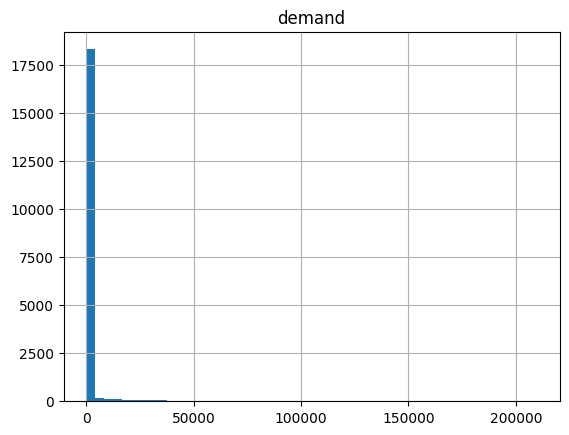

In [80]:
df_agg.select("demand").toPandas().hist(bins=50)

In [81]:
from pyspark.sql.functions import col

pdf_map = df_agg.select(
    (col("lat_bin") / 100).alias("lat"),
    (col("lon_bin") / 100).alias("lon"),
    "demand"
).toPandas()

Text(0.5, 1.0, 'NYC Taxi Demand Heatmap')

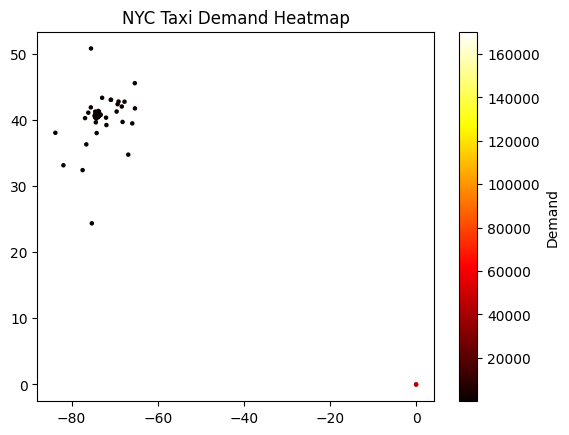

In [86]:
df_plot = df_agg.withColumn("lat", col("lat_bin") / 100) \
                .withColumn("lon", col("lon_bin") / 100)

pdf = df_plot.select("lat", "lon", "demand").sample(0.05).toPandas()

plt.scatter(pdf["lon"], pdf["lat"], c=pdf["demand"], cmap="hot", s=5)
plt.colorbar(label="Demand")
plt.title("NYC Taxi Demand Heatmap")

In [82]:
df_agg.groupBy("pickup_hour") \
    .agg(avg("demand").alias("avg_demand")) \
    .orderBy("pickup_hour") \
    .show()

+-----------+------------------+
|pickup_hour|        avg_demand|
+-----------+------------------+
|          0|2046.5325153374233|
|          1|1671.9399727148705|
|          2|1246.2817679558011|
|          3| 924.5712328767123|
|          4| 706.7616361071932|
|          5| 681.8011695906433|
|          6| 1515.554234769688|
|          7|2396.6143250688706|
|          8|2779.8151041666665|
|          9| 2751.397698209719|
|         10| 2523.956416464891|
|         11|2510.9640787949015|
|         12| 2688.339953271028|
|         13|2769.0566265060243|
|         14|2770.4572748267897|
|         15| 2694.220319634703|
|         16|2547.5844311377246|
|         17| 2824.678369195923|
|         18|  3255.45704845815|
|         19|3297.3881431767336|
+-----------+------------------+
only showing top 20 rows



In [84]:
df_agg.groupBy("lat_bin", "lon_bin") \
    .agg(avg("long_trip_ratio").alias("long_trip_ratio")) \
    .orderBy(col("long_trip_ratio").desc()) \
    .show(10)

+-------+-------+---------------+
|lat_bin|lon_bin|long_trip_ratio|
+-------+-------+---------------+
|   4066|  -7364|            1.0|
|   4060|  -7385|            1.0|
|   4073|  -7360|            1.0|
|   4074|     -1|            1.0|
|   4099|  -7384|            1.0|
|   3991|  -6806|            1.0|
|   4062|  -7373|            1.0|
|   4511|  -6950|            1.0|
|   3563|  -7800|            1.0|
|   4060|  -7384|            1.0|
+-------+-------+---------------+
only showing top 10 rows



In [87]:
df_agg.orderBy(col("demand").desc()).show(20)

+-------+-------+-----------+------+--------+------------+---------------+------------------+
|lat_bin|lon_bin|pickup_hour|demand|avg_fare|avg_distance|long_trip_ratio|        log_demand|
+-------+-------+-----------+------+--------+------------+---------------+------------------+
|   4075|  -7398|         19|209907|   10.39|        2.13|          0.013|12.254424618469756|
|   4075|  -7398|         20|206267|   10.65|        2.38|          0.018|12.236931573116157|
|   4075|  -7398|         18|202675|   10.97|        2.12|          0.016|12.219363923851384|
|   4075|  -7398|         21|193170|   11.04|        2.57|          0.024|12.171331085974225|
|   4075|  -7398|         17|170296|   11.36|        2.24|          0.026|12.045299250523803|
|   4075|  -7398|         14|163043|   12.33|        2.57|          0.054|12.001775382012324|
|   4075|  -7398|         22|160678|   11.43|        2.66|          0.028| 11.98716386490394|
|   4075|  -7398|         12|159186|   11.41|        2.26|  

In [88]:
df_agg.orderBy(col("demand").asc()).show(20)

+-------+-------+-----------+------+--------+------------+---------------+------------------+
|lat_bin|lon_bin|pickup_hour|demand|avg_fare|avg_distance|long_trip_ratio|        log_demand|
+-------+-------+-----------+------+--------+------------+---------------+------------------+
|   4052|  -7353|         13|     1|     4.5|        0.39|            0.0|0.6931471805599453|
|   4091|  -7378|          2|     1|    70.0|        2.22|            0.0|0.6931471805599453|
|   4058|  -7411|         15|     1|    40.5|        13.8|            1.0|0.6931471805599453|
|   4076|  -7402|          2|     1|     5.5|         0.9|            0.0|0.6931471805599453|
|   4670|  -7716|         19|     1|    18.5|         4.0|            0.0|0.6931471805599453|
|   4088|  -7389|          1|     1|    25.5|        8.59|            0.0|0.6931471805599453|
|   4075|  -7381|          0|     1|    14.0|        3.64|            0.0|0.6931471805599453|
|   3703|  -7550|         10|     1|    10.5|         1.7|  

In [89]:
from pyspark.sql.functions import to_date

df_clean = df_clean.withColumn(
    "pickup_date",
    to_date("pickup_datetime")
)

df_agg = df_clean.groupBy(
    "lat_bin", "lon_bin", "pickup_date", "pickup_hour"
).agg(
    count("*").alias("demand"),
    avg("fare_amount").alias("avg_fare"),
    avg("trip_distance").alias("avg_distance"),
    avg("is_long_trip").alias("long_trip_ratio")
)

Time Series Forecasting 

In [92]:
from pyspark.sql.functions import unix_timestamp, col

df_agg = df_agg.withColumn(
    "time_index",
    unix_timestamp(col("pickup_date")) + col("pickup_hour") * 3600
)

In [93]:
df_agg.select("pickup_date", "pickup_hour", "time_index").show(5)

+-----------+-----------+----------+
|pickup_date|pickup_hour|time_index|
+-----------+-----------+----------+
| 2015-01-06|         10|1420518600|
| 2015-01-12|         19|1421069400|
| 2015-01-21|          6|1421800200|
| 2015-01-23|          7|1421976600|
| 2015-01-27|         10|1422333000|
+-----------+-----------+----------+
only showing top 5 rows



In [94]:
from pyspark.sql.window import Window

window_spec = Window.partitionBy("lat_bin", "lon_bin").orderBy("time_index")

In [95]:
from pyspark.sql.functions import lag

df_agg = df_agg.withColumn("lag_1", lag("demand", 1).over(window_spec))
df_agg = df_agg.withColumn("lag_2", lag("demand", 2).over(window_spec))
df_agg = df_agg.withColumn("lag_3", lag("demand", 3).over(window_spec))

from pyspark.sql.functions import avg

df_agg = df_agg.withColumn(
    "rolling_3",
    avg("demand").over(window_spec.rowsBetween(-3, -1))
)

from pyspark.sql.functions import log1p

df_agg = df_agg.withColumn("log_demand", log1p(col("demand")))

df_final = df_agg.dropna()

In [96]:
df_final = df_final.select(
    "lat_bin",
    "lon_bin",
    "pickup_hour",
    "avg_fare",
    "avg_distance",
    "long_trip_ratio",
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_3",
    "log_demand"   # target
)

In [97]:
df_final.show(10)

+-------+-------+-----------+--------+------------+---------------+-----+-----+-----+------------------+------------------+
|lat_bin|lon_bin|pickup_hour|avg_fare|avg_distance|long_trip_ratio|lag_1|lag_2|lag_3|         rolling_3|        log_demand|
+-------+-------+-----------+--------+------------+---------------+-----+-----+-----+------------------+------------------+
|   4054|  -7401|          3|     6.5|        1.27|            0.0|    1|    3|    1|1.6666666666666667|0.6931471805599453|
|   4054|  -7401|         18|     6.0|        1.02|            0.0|    1|    1|    3|1.6666666666666667|0.6931471805599453|
|   4054|  -7401|         23|     8.0|        1.84|            0.0|    1|    1|    1|               1.0|0.6931471805599453|
|   4054|  -7401|         23|     6.0|        0.71|            0.0|    1|    1|    1|               1.0|0.6931471805599453|
|   4054|  -7401|         20|     9.5|        1.45|            0.0|    1|    1|    1|               1.0|0.6931471805599453|
|   4054

In [98]:
df_final.count()

496493

In [99]:
df_final.printSchema()

root
 |-- lat_bin: long (nullable = true)
 |-- lon_bin: long (nullable = true)
 |-- pickup_hour: integer (nullable = true)
 |-- avg_fare: double (nullable = true)
 |-- avg_distance: double (nullable = true)
 |-- long_trip_ratio: double (nullable = true)
 |-- lag_1: long (nullable = true)
 |-- lag_2: long (nullable = true)
 |-- lag_3: long (nullable = true)
 |-- rolling_3: double (nullable = true)
 |-- log_demand: double (nullable = true)



In [100]:
df_final.show(10)

+-------+-------+-----------+--------+------------+---------------+-----+-----+-----+------------------+------------------+
|lat_bin|lon_bin|pickup_hour|avg_fare|avg_distance|long_trip_ratio|lag_1|lag_2|lag_3|         rolling_3|        log_demand|
+-------+-------+-----------+--------+------------+---------------+-----+-----+-----+------------------+------------------+
|   4054|  -7401|          3|     6.5|        1.27|            0.0|    1|    3|    1|1.6666666666666667|0.6931471805599453|
|   4054|  -7401|         18|     6.0|        1.02|            0.0|    1|    1|    3|1.6666666666666667|0.6931471805599453|
|   4054|  -7401|         23|     8.0|        1.84|            0.0|    1|    1|    1|               1.0|0.6931471805599453|
|   4054|  -7401|         23|     6.0|        0.71|            0.0|    1|    1|    1|               1.0|0.6931471805599453|
|   4054|  -7401|         20|     9.5|        1.45|            0.0|    1|    1|    1|               1.0|0.6931471805599453|
|   4054

In [101]:
df_final.count()

496493

In [102]:
df_final.describe().show()

+-------+-----------------+------------------+------------------+------------------+-----------------+-------------------+-----------------+------------------+------------------+------------------+------------------+
|summary|          lat_bin|           lon_bin|       pickup_hour|          avg_fare|     avg_distance|    long_trip_ratio|            lag_1|             lag_2|             lag_3|         rolling_3|        log_demand|
+-------+-----------------+------------------+------------------+------------------+-----------------+-------------------+-----------------+------------------+------------------+------------------+------------------+
|  count|           496493|            496493|            496493|            496493|           496493|             496493|           496493|            496493|            496493|            496493|            496493|
|   mean|4073.367721196472|-7394.289043350057|11.624963493946542|16.361805560766754|4.159967884138126|0.10479705709691105|92.4537103

Module 3: Forecasting of Demand 

In [104]:
from pyspark.sql.functions import corr

lag_cols = ["lag_1", "lag_2", "lag_3", "rolling_3"]

for col_name in lag_cols:
    corr_val = df_final.select(corr("log_demand", col_name)).collect()[0][0]
    print(f"Correlation between log_demand and {col_name}: {corr_val}")

Correlation between log_demand and lag_1: 0.7584553815209365


Correlation between log_demand and lag_2: 0.7394757211409496


Correlation between log_demand and lag_3: 0.7159494769196701


Correlation between log_demand and rolling_3: 0.7503698045847679


In [105]:
from pyspark.sql.functions import avg

hourly_pattern = df_final.groupBy("pickup_hour") \
    .agg(avg("log_demand").alias("avg_log_demand")) \
    .orderBy("pickup_hour")

hourly_pattern.show(24)

+-----------+------------------+
|pickup_hour|    avg_log_demand|
+-----------+------------------+
|          0| 2.385596619513028|
|          1|2.2327624688956433|
|          2| 2.124027808423105|
|          3|2.0492186606277483|
|          4|2.0091683113822896|
|          5|2.0621999868359966|
|          6| 2.313809820156183|
|          7| 2.499255955033702|
|          8|2.5940643031524218|
|          9| 2.634412881238861|
|         10|2.6429966122988104|
|         11|2.6580975928062034|
|         12| 2.663007389389515|
|         13|2.6585036847241175|
|         14| 2.631471043268626|
|         15|2.5966605900578346|
|         16|2.5718946436691548|
|         17|2.6608215861539226|
|         18| 2.722905922921129|
|         19|2.6950624687460976|
|         20| 2.641370078680325|
|         21|2.6008750180293676|
|         22|2.5723449512396344|
|         23|2.4982201098981625|
+-----------+------------------+



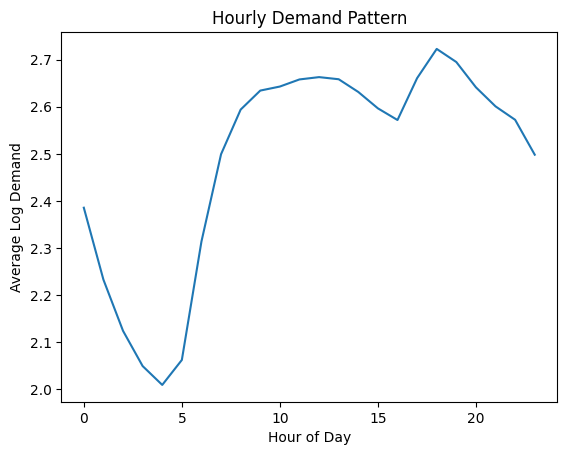

In [106]:
import matplotlib.pyplot as plt

pdf = hourly_pattern.toPandas()

plt.plot(pdf["pickup_hour"], pdf["avg_log_demand"])
plt.xlabel("Hour of Day")
plt.ylabel("Average Log Demand")
plt.title("Hourly Demand Pattern")
plt.show()

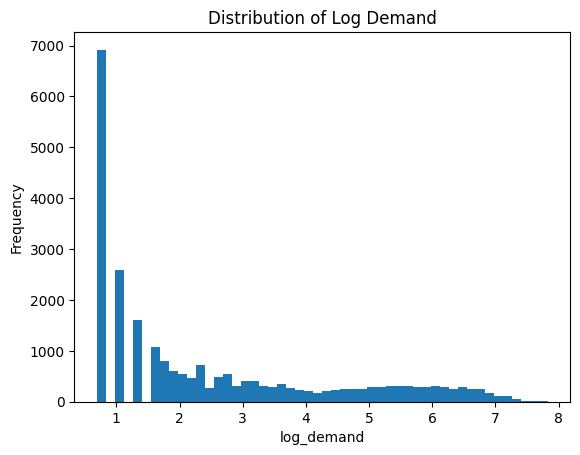

In [107]:
import matplotlib.pyplot as plt

sample_df = df_final.sample(fraction=0.05, seed=42).toPandas()

plt.hist(sample_df["log_demand"], bins=50)
plt.title("Distribution of Log Demand")
plt.xlabel("log_demand")
plt.ylabel("Frequency")
plt.show()

In [108]:
feature_cols = ["avg_fare", "avg_distance", "long_trip_ratio"]

for col_name in feature_cols:
    corr_val = df_final.select(corr("log_demand", col_name)).collect()[0][0]
    print(f"Correlation between log_demand and {col_name}: {corr_val}")

Correlation between log_demand and avg_fare: -0.1590945104986878


Correlation between log_demand and avg_distance: -0.13847567250675585


Correlation between log_demand and long_trip_ratio: -0.09504083366940769


In [109]:
region_demand = df_final.groupBy("lat_bin", "lon_bin") \
    .agg(avg("log_demand").alias("avg_log_demand"))

region_demand.orderBy("avg_log_demand", ascending=False).show(10)

+-------+-------+------------------+
|lat_bin|lon_bin|    avg_log_demand|
+-------+-------+------------------+
|   4075|  -7398| 6.529865911864774|
|   4076|  -7399| 6.424228293830515|
|   4074|  -7399|6.3934681487135725|
|   4075|  -7399| 6.378380915649992|
|   4075|  -7400| 6.249087961429334|
|   4074|  -7400| 6.224935171027935|
|   4073|  -7399| 6.118357011685919|
|   4077|  -7396| 6.093567371387965|
|   4076|  -7397| 6.080391467659655|
|   4076|  -7398| 6.016979756729592|
+-------+-------+------------------+
only showing top 10 rows



In [116]:
from pyspark.sql.functions import to_date, hour, col

df = df_clean \
    .withColumn("pickup_date", to_date(col("pickup_datetime"))) \
    .withColumn("pickup_hour", hour(col("pickup_datetime")))

In [117]:
from pyspark.sql.functions import count, avg, when

df_agg = df.groupBy(
    "lat_bin",
    "lon_bin",
    "pickup_date",
    "pickup_hour"
).agg(
    count("*").alias("demand"),
    avg("fare_amount").alias("avg_fare"),
    avg("trip_distance").alias("avg_distance"),
    avg(when(col("trip_distance") > 10, 1).otherwise(0)).alias("long_trip_ratio")
)

In [118]:
from pyspark.sql.functions import concat_ws, lpad, to_timestamp

df_agg = df_agg.withColumn(
    "hour_str",
    lpad(col("pickup_hour").cast("string"), 2, "0")
).withColumn(
    "datetime_str",
    concat_ws(" ", col("pickup_date"), col("hour_str"))
).withColumn(
    "datetime",
    to_timestamp(col("datetime_str"), "yyyy-MM-dd HH")
)

In [119]:
from pyspark.sql.window import Window
from pyspark.sql.functions import lag

window_spec = Window.partitionBy("lat_bin", "lon_bin").orderBy("datetime")

df_final = df_agg \
    .withColumn("lag_1", lag("demand", 1).over(window_spec)) \
    .withColumn("lag_2", lag("demand", 2).over(window_spec)) \
    .withColumn("lag_3", lag("demand", 3).over(window_spec))

In [120]:
from pyspark.sql.functions import log1p

df_final = df_final.withColumn(
    "log_demand",
    log1p(col("demand"))
)

In [123]:
from pyspark.sql.functions import avg

rolling_window = Window.partitionBy("lat_bin", "lon_bin") \
    .orderBy("datetime") \
    .rowsBetween(-3, -1)

df_final = df_final.withColumn(
    "rolling_3",
    avg("demand").over(rolling_window)
)

In [124]:
df_final = df_final.dropna()

In [125]:
df_final.printSchema()

root
 |-- lat_bin: long (nullable = true)
 |-- lon_bin: long (nullable = true)
 |-- pickup_date: date (nullable = true)
 |-- pickup_hour: integer (nullable = true)
 |-- demand: long (nullable = false)
 |-- avg_fare: double (nullable = true)
 |-- avg_distance: double (nullable = true)
 |-- long_trip_ratio: double (nullable = true)
 |-- hour_str: string (nullable = true)
 |-- datetime_str: string (nullable = false)
 |-- datetime: timestamp (nullable = true)
 |-- lag_1: long (nullable = true)
 |-- lag_2: long (nullable = true)
 |-- lag_3: long (nullable = true)
 |-- log_demand: double (nullable = true)
 |-- rolling_3: double (nullable = true)



In [126]:
from pyspark.sql.functions import corr

for col_name in ["lag_1", "lag_2", "lag_3", "rolling_3"]:
    print(col_name, df_final.select(corr("log_demand", col_name)).collect()[0][0])

lag_1 0.7584716943969824


lag_2 0.7394764817978576


lag_3 0.7159464769361223


rolling_3 0.7503742250080613


In [127]:
df_final.selectExpr("min(datetime)", "max(datetime)").show()


+-------------------+-------------------+
|      min(datetime)|      max(datetime)|
+-------------------+-------------------+
|2015-01-01 04:00:00|2016-03-31 23:00:00|
+-------------------+-------------------+



In [130]:
from pyspark.sql.functions import col, unix_timestamp

df_final = df_final.withColumn(
    "datetime_num",
    unix_timestamp(col("datetime"))
)

quantiles = df_final.approxQuantile("datetime_num", [0.7, 0.85], 0.01)

train_end = quantiles[0]
val_end   = quantiles[1]

train_df = df_final.filter(col("datetime_num") <= train_end)

val_df = df_final.filter(
    (col("datetime_num") > train_end) &
    (col("datetime_num") <= val_end)
)

test_df = df_final.filter(col("datetime_num") > val_end)

In [131]:
print("Train:", train_df.count())
print("Val:", val_df.count())
print("Test:", test_df.count())

Train: 343432


Val: 73822


Test: 78214


In [132]:
train_df.selectExpr("min(datetime)", "max(datetime)").show()
val_df.selectExpr("min(datetime)", "max(datetime)").show()
test_df.selectExpr("min(datetime)", "max(datetime)").show()

+-------------------+-------------------+
|      min(datetime)|      max(datetime)|
+-------------------+-------------------+
|2015-01-01 04:00:00|2016-02-24 11:00:00|
+-------------------+-------------------+



+-------------------+-------------------+
|      min(datetime)|      max(datetime)|
+-------------------+-------------------+
|2016-02-24 12:00:00|2016-03-13 03:00:00|
+-------------------+-------------------+



+-------------------+-------------------+
|      min(datetime)|      max(datetime)|
+-------------------+-------------------+
|2016-03-13 04:00:00|2016-03-31 23:00:00|
+-------------------+-------------------+



In [133]:
from pyspark.sql.functions import col

val_baseline = val_df.withColumn(
    "baseline_pred",
    col("lag_1")
)

In [134]:
val_baseline = val_baseline.withColumn(
    "ma_pred",
    (col("lag_1") + col("lag_2") + col("lag_3")) / 3
)

In [137]:
val_baseline.columns

['lat_bin',
 'lon_bin',
 'pickup_date',
 'pickup_hour',
 'demand',
 'avg_fare',
 'avg_distance',
 'long_trip_ratio',
 'hour_str',
 'datetime_str',
 'datetime',
 'lag_1',
 'lag_2',
 'lag_3',
 'log_demand',
 'rolling_3',
 'datetime_num',
 'baseline_pred',
 'ma_pred']

In [140]:
from pyspark.sql.functions import exp
val_baseline = val_baseline.withColumn(
    "actual_demand",
    exp(col("log_demand")) - 1
)

In [141]:
val_eval = val_baseline.select(
    abs(col("actual_demand") - col("baseline_pred")).alias("baseline_error"),
    abs(col("actual_demand") - col("ma_pred")).alias("ma_error"),
    ((col("actual_demand") - col("baseline_pred"))**2).alias("baseline_sq"),
    ((col("actual_demand") - col("ma_pred"))**2).alias("ma_sq")
)

In [144]:
from pyspark.sql.functions import mean, sqrt

val_metrics = val_eval.agg(
    mean("baseline_error").alias("baseline_MAE"),
    mean("ma_error").alias("ma_MAE"),
    sqrt(mean("baseline_sq")).alias("baseline_RMSE"),
    sqrt(mean("ma_sq")).alias("ma_RMSE")
)

val_metrics.show()

+-----------------+------------------+------------------+-----------------+
|     baseline_MAE|            ma_MAE|     baseline_RMSE|          ma_RMSE|
+-----------------+------------------+------------------+-----------------+
|20.22222372734415|30.421951902323602|57.599933713451364|86.73174928898324|
+-----------------+------------------+------------------+-----------------+



In [145]:
df_final.write.mode("overwrite").parquet("df_final.parquet")

In [146]:
train_df.write.mode("overwrite").parquet("train_df.parquet")
val_df.write.mode("overwrite").parquet("val_df.parquet")
test_df.write.mode("overwrite").parquet("test_df.parquet")

In [147]:
df_final = spark.read.parquet("df_final.parquet")
train_df = spark.read.parquet("train_df.parquet")
val_df = spark.read.parquet("val_df.parquet")
test_df = spark.read.parquet("test_df.parquet")

26/04/03 15:27:39 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 728148 ms exceeds timeout 120000 ms
26/04/03 15:27:39 WARN SparkContext: Killing executors is not supported by current scheduler.
26/04/03 15:27:41 WARN Executor: Issue communicating with driver in heartbeater
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:56)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:310)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:101)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:85)
	at org.apache.spark.storage.BlockManagerMaster.registerBlockManager(BlockManagerMaster.scala:80)
	at org.apache.spark.storage.BlockManager.reregister(BlockManager.scala:642)
	at org.apache.spark.executor.Executor.reportHeartBeat(Executor.scala:1223)
	at o